# Actividad 4: comparación de modelos de sentimientos en español

Dataset sintético de 30 opiniones, creado para esta práctica. No son reseñas reales. Los resultados solo representan este conjunto pequeño.

**Importante:** se comparan modelos de 3 clases; el modelo de 5 estrellas se convierte a NEG (1–2), NEU (3) y POS (4–5).

## 1. Configuración y dependencias
Se activa GPU en Entorno de ejecución. La comparación reportará también el hardware utilizado.

In [3]:
%pip install -q \
    "pandas==2.2.3" \
    "transformers==4.57.6" \
    "huggingface-hub==0.36.2" \
    "accelerate>=0.34,<2" \
    "scikit-learn>=1.4" \
    matplotlib \
    safetensors

In [4]:
import os, time, json, platform, shutil
import numpy as np
import pandas as pd
import torch
from transformers import pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
import matplotlib.pyplot as plt
print("Python:", platform.python_version())
print("PyTorch:",torch.__version__)
print("GPU disponible:",torch.cuda.is_available())
if torch.cuda.is_available(): print("GPU:",torch.cuda.get_device_name(0))
else: print("ADVERTENCIA: sin GPU; activar acelerador GPU para cumplir la rúbrica")
DEVICE=0 if torch.cuda.is_available() else -1

Python: 3.13.15
PyTorch: 2.11.0+cu130
GPU disponible: True
GPU: Tesla T4


## 2. Configuración Hugging Face
Los modelos públicos no requieren token. Si se requiere autenticar en Hugging Face camb iar `HF_TOKEN` por un token real.

In [5]:
try:
 from google.colab import userdata
 token=userdata.get("NO_TOKEN") #Se usarán modelos públicos
 if token:
  from huggingface_hub import login
  login(token=token,add_to_git_credential=False)
  print("Autenticación realizada")
 else: print("Sin token: se usarán modelos públicos")
except Exception as e:
 print("Autenticación opcional no realizada:",type(e).__name__)

Autenticación opcional no realizada: SecretNotFoundError


## 3. Cargar y revisar el dataset
Se debe cargar `opiniones_supermercado.csv` en los `Archivos` y en carpeta `data`. Los textos y etiquetas son sintéticos, no observaciones de una empresa real.

In [7]:
from pathlib import Path
path=Path("data/opiniones_supermercado.csv") #Si se requiere cambiar la carpeta data, debe ser aqui
if not path.exists(): #Si el archivo no existe en data, lo buscará fuera
 path=Path("opiniones_supermercado.csv")
if not path.exists(): #Si el archivo no existe, se muestra un buscador para cargarlo
 from google.colab import files
 print("Sube opiniones_supermercado.csv")
 uploaded=files.upload()
 path=Path("opiniones_supermercado.csv")
df=pd.read_csv(path)
assert set(["id","texto","etiqueta"]).issubset(df.columns)
assert set(df.etiqueta)=={"NEG","NEU","POS"}
print(df.etiqueta.value_counts())
display(df.head())

etiqueta
POS    10
NEG    10
NEU    10
Name: count, dtype: int64


,id,texto,etiqueta,origen
0,OP001,La entrega llegó a tiempo y los productos esta...,POS,Ejemplo sintético redactado para esta práctica
1,OP002,Encontré todo lo que buscaba y el personal fue...,POS,Ejemplo sintético redactado para esta práctica
2,OP003,La aplicación fue sencilla y el pedido llegó c...,POS,Ejemplo sintético redactado para esta práctica
3,OP004,Los precios fueron claros y la compra resultó ...,POS,Ejemplo sintético redactado para esta práctica
4,OP005,Las frutas estaban en buen estado y bien empac...,POS,Ejemplo sintético redactado para esta práctica


## 4. Inferencia con tres modelos
Se ejecutarán los tres modelos sobre exactamente las mismas 30 opiniones. El tiempo de carga se mide por separado de la latencia de inferencia. Una primera predicción prepara el modelo antes de medir.

In [8]:
MODELOS={"RoBERTuito":"pysentimiento/robertuito-sentiment-analysis","XLM-RoBERTa":"cardiffnlp/twitter-xlm-roberta-base-sentiment","BERT multilingüe":"nlptown/bert-base-multilingual-uncased-sentiment"}
def normalizar(label):
 s=str(label).strip().lower()
 if "star" in s:
  n=int(s[0]);return "NEG" if n<=2 else "NEU" if n==3 else "POS"
 if s in ("neg","negative","label_0"):return "NEG"
 if s in ("neu","neutral","label_1"):return "NEU"
 if s in ("pos","positive","label_2"):return "POS"
 raise ValueError("Etiqueta inesperada: "+str(label))

resultados=[]; predicciones=[]
for nombre,repo in MODELOS.items():
 print("Evaluando:",nombre,repo)
 inicio=time.perf_counter()
 clf=pipeline("text-classification",model=repo,tokenizer=repo,device=DEVICE)
 carga=time.perf_counter()-inicio
 _=clf("Esta compra fue excelente",truncation=True)
 if torch.cuda.is_available():torch.cuda.synchronize()
 inicio=time.perf_counter()
 salidas=[clf(texto,truncation=True,max_length=256)[0] for texto in df.texto]
 if torch.cuda.is_available():torch.cuda.synchronize()
 duracion=time.perf_counter()-inicio
 pred=[normalizar(o["label"]) for o in salidas]
 y=df.etiqueta.tolist()
 precision,recall,f1,_=precision_recall_fscore_support(y,pred,average="macro",zero_division=0)
 resultados.append({"modelo":nombre,"repositorio":repo,"accuracy":accuracy_score(y,pred),"precision_macro":precision,"recall_macro":recall,"f1_macro":f1,"carga_s":carga,"inferencia_total_s":duracion,"latencia_media_ms":1000*duracion/len(df),"n":len(df),"gpu":torch.cuda.is_available()})
 predicciones.extend([{"id":id_,"modelo":nombre,"real":real,"prediccion":pr,"confianza":o["score"]} for id_,real,pr,o in zip(df.id,y,pred,salidas)])
 print(classification_report(y,pred,labels=["NEG","NEU","POS"],zero_division=0))
 del clf
 if torch.cuda.is_available():torch.cuda.empty_cache()
metricas=pd.DataFrame(resultados)
display(metricas)

Evaluando: RoBERTuito pysentimiento/robertuito-sentiment-analysis


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/435M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Device set to use cuda:0


              precision    recall  f1-score   support

         NEG       0.91      1.00      0.95        10
         NEU       1.00      0.30      0.46        10
         POS       0.62      1.00      0.77        10

    accuracy                           0.77        30
   macro avg       0.84      0.77      0.73        30
weighted avg       0.84      0.77      0.73        30



,modelo,repositorio,accuracy,precision_macro,recall_macro,f1_macro,carga_s,inferencia_total_s,latencia_media_ms,n,gpu
0,RoBERTuito,pysentimiento/robertuito-sentiment-analysis,0.833333,0.863095,0.833333,0.833333,10.421065,0.377817,12.593889,30,True
1,XLM-RoBERTa,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.933333,0.944444,0.933333,0.932660,18.855573,0.677037,22.567886,30,True
2,BERT multilingüe,nlptown/bert-base-multilingual-uncased-sentiment,0.766667,0.844697,0.766667,0.727717,11.133552,0.339867,11.328909,30,True


## 5. Comparación visual y análisis
La precisión, recall y F1 son macro-promedios, para que las tres clases tengan el mismo peso. La latencia es una medición local.
Se generan los gráficos de comparación y latencia.

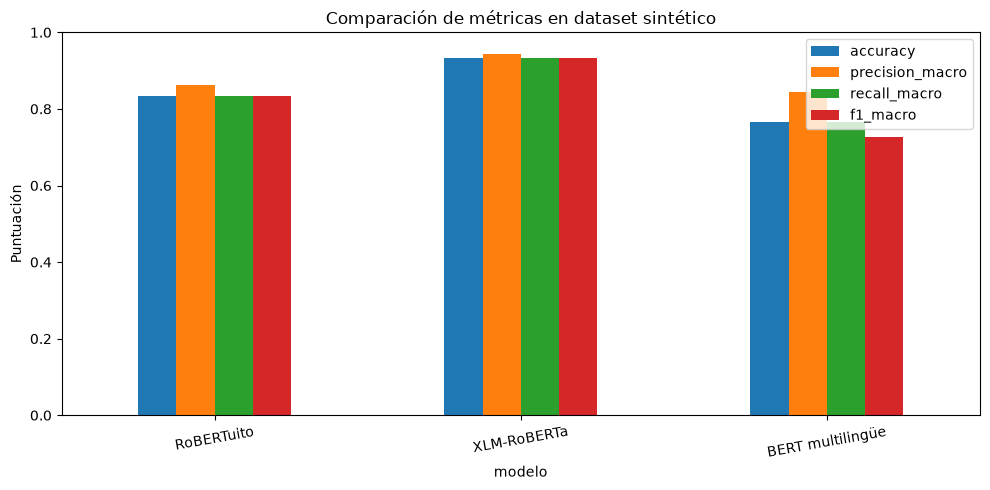

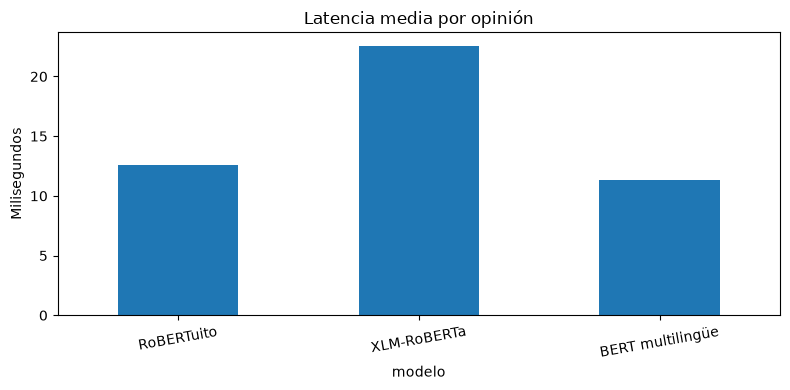

In [9]:
ax=metricas.set_index("modelo")[["accuracy","precision_macro","recall_macro","f1_macro"]].plot(kind="bar",figsize=(10,5),ylim=(0,1),rot=10,title="Comparación de métricas en dataset sintético")
ax.set_ylabel("Puntuación")
plt.tight_layout();plt.savefig("metricas_modelos.png",dpi=170);plt.show()
ax=metricas.plot.bar(x="modelo",y="latencia_media_ms",legend=False,figsize=(8,4),rot=10,title="Latencia media por opinión")
ax.set_ylabel("Milisegundos")
plt.tight_layout();plt.savefig("latencia_modelos.png",dpi=170);plt.show()

## 6. Guardar resultados y conclusiones parciales
El modelo con mayor F1 macro no necesariamente es el más rápido. La selección final debe considerar latencia, tamaño, recursos, y probar con datos reales representativos.

In [10]:
metricas.to_csv("comparacion_modelos.csv",index=False,encoding="utf-8-sig")
pd.DataFrame(predicciones).to_csv("predicciones_modelos.csv",index=False,encoding="utf-8-sig")
mejor=metricas.sort_values(["f1_macro","latencia_media_ms"],ascending=[False,True]).iloc[0]
print("Mayor F1 macro en este dataset:",mejor.modelo,"F1=",round(mejor.f1_macro,4))
print("Menor latencia en esta ejecución:",metricas.sort_values("latencia_media_ms").iloc[0].modelo)
print("No extrapolar estos resultados a opiniones reales sin validación externa")
from google.colab import files
for f in ["comparacion_modelos.csv","predicciones_modelos.csv","metricas_modelos.png","latencia_modelos.png"]: files.download(f)

Mayor F1 macro en este dataset: XLM-RoBERTa F1= 0.9327
Menor latencia en esta ejecución: BERT multilingüe
No extrapolar estos resultados a opiniones reales sin validación externa


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>